# Phase 3 write-up: catching contamination false positives by ephemeris matching (11/08/2026)

Phase 2 left contamination as a blind spot: Phase 2a still missed 18% of the "EC only" false positives
(catalog family, p = 0.5) and 44% at the 98% planet-recall headline. Many of those KOIs are **another star's
signal leaking into the target's pixels**, through PSF overlap, column bleed or electronic cross-talk. Nothing
measured on the target alone can show that, because the evidence lives on the other star.

Kepler's robovetter catches them by **ephemeris matching**: does the KOI's period and transit time match a signal
on another star? Phase 3 (`PHASE3_PLAN.md`) rebuilds that test from catalog data only and gives it to the model as
features, in a **separate "+ ephemeris" family**. The test is partly circular with the EC flag, just as the
centroid features are with Kepler's centroid test, so the two Phase 2 models stay unchanged.

1. **M1, matching:** the score, and the random-epoch null that fixed the design without labels.
2. **M1, pool check:** what the features look like per class.
3. **M2, CV:** the two "+ ephemeris" models vs Phase 2a on identical folds (5 fold shuffles × 10 seeds, paired star
   bootstrap).
4. **Blind spots:** the plan's success criteria.
5. **Operating points**, and the low-FP-rate comparison with the robovetter's `koi_score`.
6. **v2:** adding the Kepler eclipsing-binary catalog.
7. Conclusions.

**CV only.** The sealed test split was scored once per phase and is spent, so it is not used here. Labels and
robovetter flags only group KOIs; they are never inputs. The other catalogs contribute only period, epoch, depth,
duration, position and brightness, never their dispositions, and a KOI is never matched to its own star.

In [1]:
include(joinpath(@__DIR__, "..", "src", "VettingSetup.jl"))
df_raw = load_koi()
pool, _ = cv_pool(clean_koi(df_raw))
y = Float64.(pool.label)
dr = is_dr25(pool, df_raw)
fpat = with_vetting_info(pool, df_raw, zeros(nrow(pool))).flag_pattern
ec_any = coalesce.(leftjoin(pool[:, [:kepoi_name]], df_raw[:, [:kepoi_name, :koi_fpflag_ec]];
                            on = :kepoi_name, order = :left).koi_fpflag_ec, 0) .== 1
F = CSV.read(joinpath(CV_DIR, "p3_ephemeris.csv"), DataFrame)
pool = leftjoin(pool, F[:, [:kepoi_name; EPHEMERIS_FEATURES]]; on = :kepoi_name, order = :left)
readres(f) = CSV.read(joinpath(CV_DIR, f), DataFrame)
@printf("pool: %d KOIs (%d DR25, %d supplemental); planets %d, FPs %d; EC-only FPs %d, EC-flagged FPs %d\n",
        nrow(pool), sum(dr), sum(.!dr), sum(y .== 1), sum(y .== 0), sum((y .== 0) .& (fpat .== "EC")),
        sum((y .== 0) .& ec_any))

VettingSetup loaded:11 features, data at C:\JuliaProjects\Exoplanet vetting\data\koi_cumulative.csv
┌ Info: clean_koi
│   raw = 9564
│   kept = 9201
│   stars = 7927
│   planets = 4619
└   false_pos = 4582
pool: 8288 KOIs (7199 DR25, 1089 supplemental); planets 4163, FPs 4125; EC-only FPs 111, EC-flagged FPs 1022


## 1. Matching, and the null that fixed the design (M1)

**Entries**, the possible sources: every KOI (9,564) and every DR25 TCE (34,032), from `data/catalogs/`
(`sweeps/p3_download.jl`). **Score** for target A against entry B on another star, at period ratio m:n, in units of
A's transit duration:
- *drift* = (1460 d / P_A) · |P_A − (m/n) P_B|: how far the two ephemerides walk apart over the mission;
- *offset*: the gap between A's transits and B's at A's epoch;
- score = √(drift² + offset²). Below ~1 the two signals coincide for the whole mission.

**The null:** shift every entry's epoch by a random fraction of its period, which destroys real coincidences and
keeps chance ones, then match again. The first design (all 63 ratios m:n ≤ 10, any separation) "matched" ~90% of
KOIs, and so did the null: pure chance. Real matches sit **close on the sky, at simple ratios, with tight scores**.
The v1 features therefore use ratios 1:1, 1:2 and 2:1 only:

| Feature | Meaning (no match → the search limit, never a missing indicator) |
|---|---|
| `eph_score_near` | best score among matches within 10′ |
| `eph_logsep` | log10 separation of that match [″] |
| `eph_logleak` | log10 of the leak fraction the other signal needs to make our depth, (δ_A/δ_B)·10^(0.4(m_B − m_A)); < 0 means it could |
| `eph_dmag` | its Kepler magnitude − ours |
| `eph_nmatch_near` | other stars within 10′ matched with score < 0.25 |
| `eph_score_far` | best 1:1 score beyond 10′ (cross-talk candidates; mostly chance, the model weighs it) |

Below: the best near score for real vs one random-epoch draw (no labels), recomputed here (~20 s).

near match < 0.25: real 1400 KOIs, null 388 -> excess 1012 (KOIs with the EC flag: 1148)


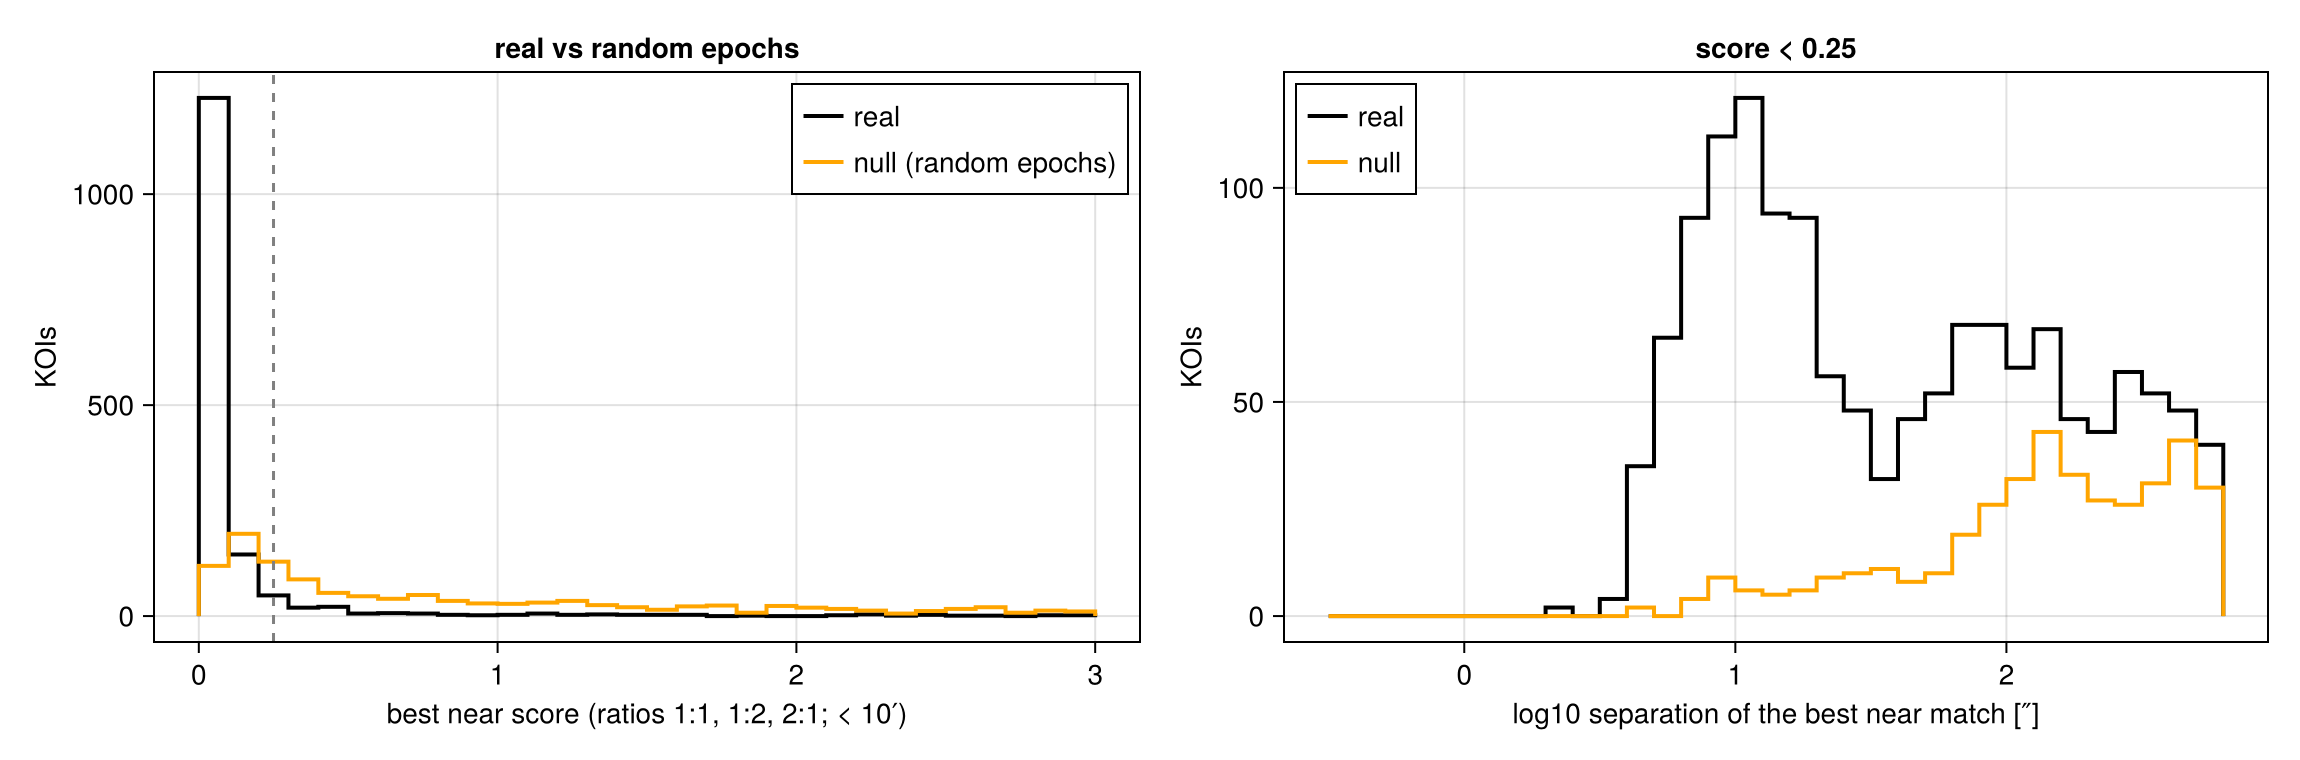

In [2]:
entries = ephemeris_entries(df_raw)
M = ephemeris_matches(df_raw, entries)
Mn = ephemeris_matches(df_raw, entries; rng = Random.Xoshiro(1))
Fr, Fn = ephemeris_features(df_raw, M), ephemeris_features(df_raw, Mn)
fig = Figure(size = (1150, 380))
ax = Axis(fig[1, 1]; xlabel = "best near score (ratios 1:1, 1:2, 2:1; < 10′)", ylabel = "KOIs", title = "real vs random epochs")
edges = 0:0.1:3
for (d, lab, c) in ((Fr, "real", :black), (Fn, "null (random epochs)", :orange))
    stephist!(ax, filter(<(3), d.eph_score_near); bins = edges, color = c, label = lab, linewidth = 2)
end
vlines!(ax, [MATCH_CUT]; color = :gray, linestyle = :dash); axislegend(ax; position = :rt)
ax2 = Axis(fig[1, 2]; xlabel = "log10 separation of the best near match [″]", ylabel = "KOIs", title = "score < 0.25")
for (d, lab, c) in ((Fr, "real", :black), (Fn, "null", :orange))
    stephist!(ax2, d.eph_logsep[d.eph_score_near .< MATCH_CUT]; bins = -0.5:0.1:2.8, color = c, label = lab, linewidth = 2)
end
axislegend(ax2; position = :lt)
@printf("near match < %.2f: real %d KOIs, null %d -> excess %d (KOIs with the EC flag: %d)\n", MATCH_CUT,
        sum(Fr.eph_score_near .< MATCH_CUT), sum(Fn.eph_score_near .< MATCH_CUT),
        sum(Fr.eph_score_near .< MATCH_CUT) - sum(Fn.eph_score_near .< MATCH_CUT), sum(coalesce.(df_raw.koi_fpflag_ec, 0) .== 1))
fig

Real matches pile up at scores near 0, while chance matches spread evenly in score. The excess, about 1,000 KOIs,
is close to the 1,148 KOIs Kepler flagged EC. Chance matches grow with separation (more sky, more stars), which
is why separation is a feature and why the far-field score is kept apart.

## 2. Pool check per class (M1, after the features were fixed)

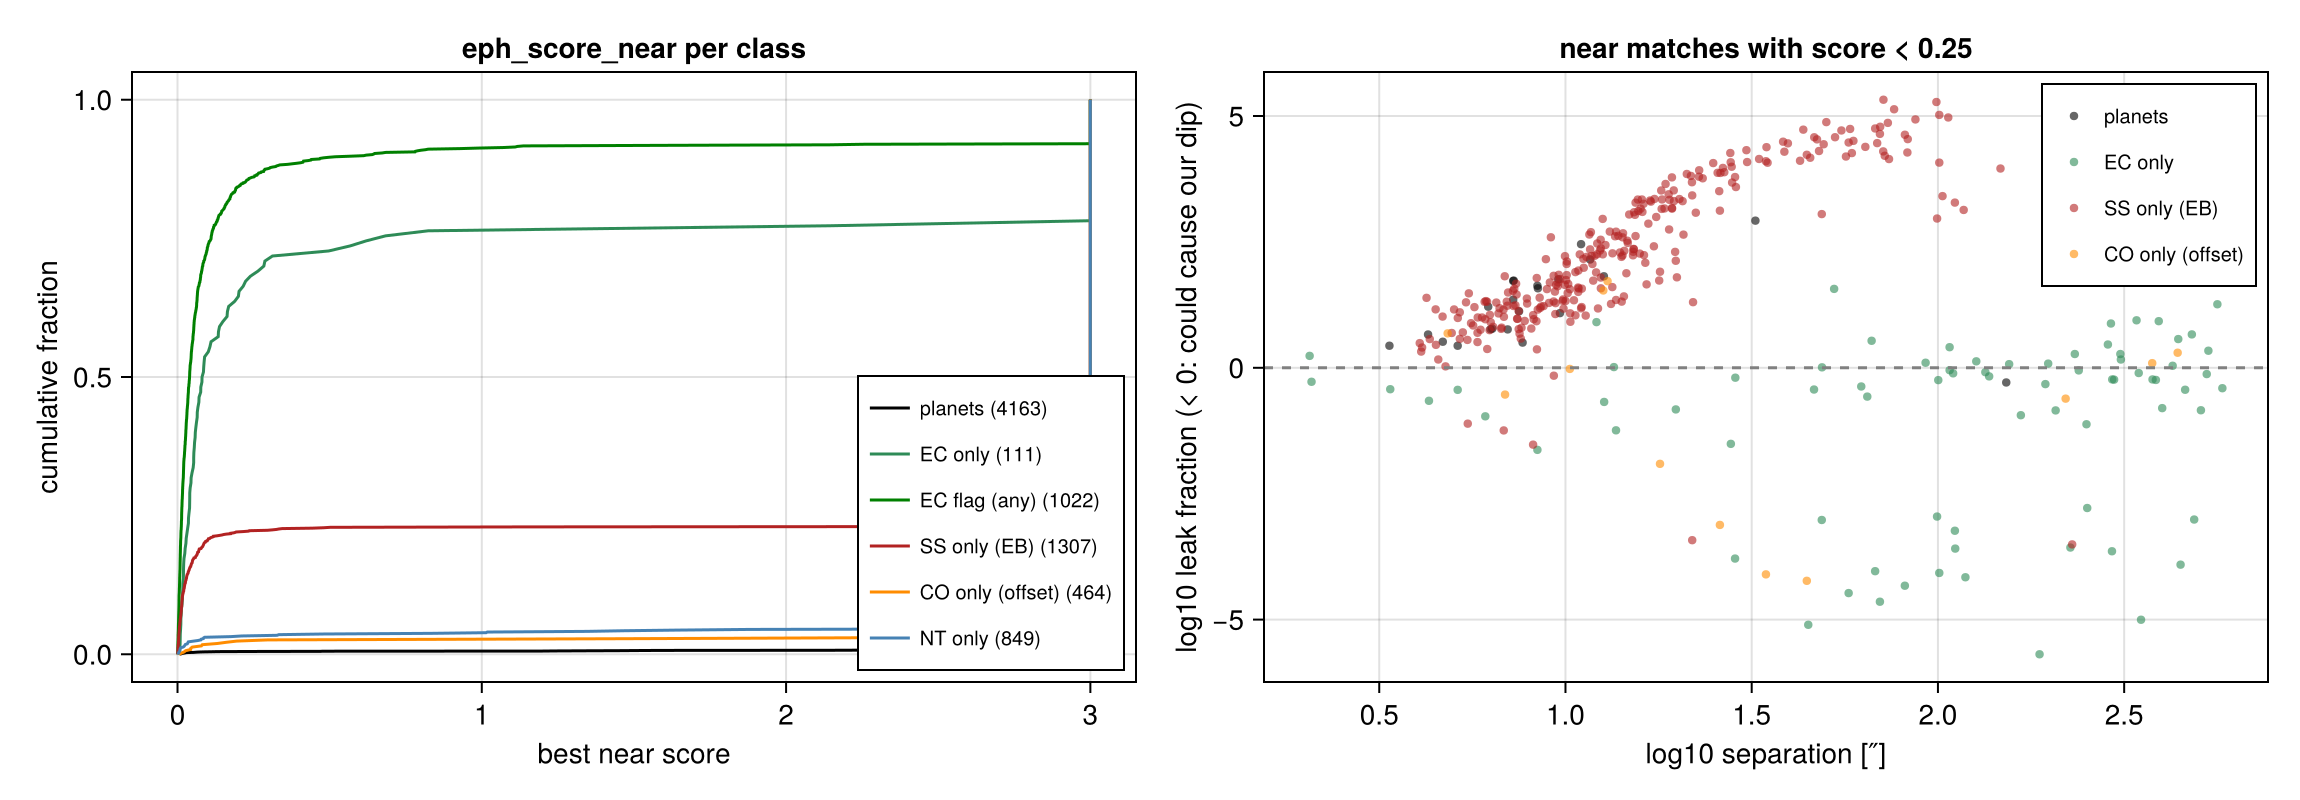

In [3]:
classes = [("planets", y .== 1), ("EC only", (y .== 0) .& (fpat .== "EC")), ("EC flag (any)", (y .== 0) .& ec_any),
           ("SS only (EB)", (y .== 0) .& (fpat .== "SS")), ("CO only (offset)", (y .== 0) .& (fpat .== "CO")),
           ("NT only", (y .== 0) .& (fpat .== "NT"))]
cols = [:black, :seagreen, :green, :firebrick, :darkorange, :steelblue]
fig = Figure(size = (1150, 400))
ax = Axis(fig[1, 1]; xlabel = "best near score", ylabel = "cumulative fraction", title = "eph_score_near per class")
for ((name, m), c) in zip(classes, cols)
    v = sort(coalesce.(pool.eph_score_near[m], 3.0))
    lines!(ax, v, range(0, 1; length = length(v)); color = c, label = "$name ($(sum(m)))")
end
axislegend(ax; position = :rb, labelsize = 10)
ax2 = Axis(fig[1, 2]; xlabel = "log10 separation [″]", ylabel = "log10 leak fraction (< 0: could cause our dip)",
           title = "near matches with score < 0.25")
for ((name, m), c) in zip(classes[[1, 2, 4, 5]], cols[[1, 2, 4, 5]])
    k = m .& (coalesce.(pool.eph_score_near, 3.0) .< MATCH_CUT)
    scatter!(ax2, pool.eph_logsep[k], clamp.(coalesce.(pool.eph_logleak[k], NaN), -6, 6); color = (c, 0.6),
             markersize = 6, label = name)
end
hlines!(ax2, [0]; color = :gray, linestyle = :dash); axislegend(ax2; position = :rt, labelsize = 10)
fig

- **Contamination FPs match; planets almost never do.** A tight near match exists for 68.5% of EC-only FPs and
  86% of all EC-flagged FPs, vs 0.5% of planets.
- The eclipsing-binary FPs that match (22%) are mostly the **sources**: their leak fraction is > 0, so the matched
  star could not have caused their eclipses; it is the other way round. The leak feature separates victim from
  source.
- Alone, the near score separates EC-only FPs from planets with AUC 0.90.

## 3. M2: the two "+ ephemeris" models vs Phase 2a (CV)

The same learners, hyperparameters and folds as Phase 2a (MLP + EvoTrees, 50/50; `sweeps/p3_cv.jl`, 13 min for all
four runs at 2 threads). Paired star bootstrap, 1,000 resamples (`sweeps/p3_m2.jl`).

In [4]:
readres("p3_m2_summary.csv")

Row,family,subset,n,old,auc_old,new,auc_new,delta,ci_lo,ci_hi
,DataStri…,DataStri…,Int64,DataStri…,Float64,DataStri…,Float64,Float64,Float64,Float64
1,catalog,DR25 KOIs,7199,Phase 2a,0.9705,+ ephemeris,0.9764,0.0059,0.0042,0.0075
2,catalog,supplemental KOIs,1089,Phase 2a,0.6959,+ ephemeris,0.6979,0.002,-0.0055,0.0098
3,catalog,all pool,8288,Phase 2a,0.9536,+ ephemeris,0.9605,0.0069,0.0052,0.0087
4,+ centroid,DR25 KOIs,7199,Phase 2a,0.9869,+ ephemeris,0.9889,0.002,0.0013,0.0027
5,+ centroid,supplemental KOIs,1089,Phase 2a,0.7661,+ ephemeris,0.769,0.0029,-0.0031,0.0097
6,+ centroid,all pool,8288,Phase 2a,0.9752,+ ephemeris,0.9778,0.0026,0.0018,0.0035


Both families gain on DR25 KOIs, with CIs above 0: **0.971 → 0.976** (catalog) and **0.987 → 0.989**
(+ centroid). Every single learner gains too (trees +0.006 / +0.002, MLP +0.007 / +0.002, `sweeps/results/p3_cv.log`).
The supplemental KOIs barely move (CIs include 0), as expected: few of them are contamination cases.

## 4. Blind spots: the plan's success criteria

Nested hard calls (thresholds chosen on the other folds), mean over the 5 fold shuffles, on the whole pool as in
Phase 2's M5. "new − old" with a paired star-bootstrap 95% CI.

36×9 DataFrame
 Row │ group                       n      family      rule               old_pct  new_pct  delta_pct  ci_lo    ci_hi
     │ DataStri…                   Int64  DataStri…   DataStri…          Float64  Float64  Float64    Float64  Float64
─────┼─────────────────────────────────────────────────────────────────────────────────────────────────────────────────
   1 │ FP missed: EC only            111  catalog     p = 0.5               18.0      4.3      -13.7    -20.5     -7.1
   2 │ FP missed: EC only            111  catalog     planet recall 98%     44.3     15.0      -29.4    -36.6    -21.6
   3 │ FP missed: EC only            111  + centroid  p = 0.5               23.2      6.7      -16.6    -23.3    -10.0
   4 │ FP missed: EC only            111  + centroid  planet recall 98%     33.7     13.3      -20.4    -27.7    -13.3
   5 │ FP missed: EC flag (any)     1022  catalog     p = 0.5                8.1      0.8       -7.3     -9.0     -5.7
   6 │ FP missed: EC flag (any)   

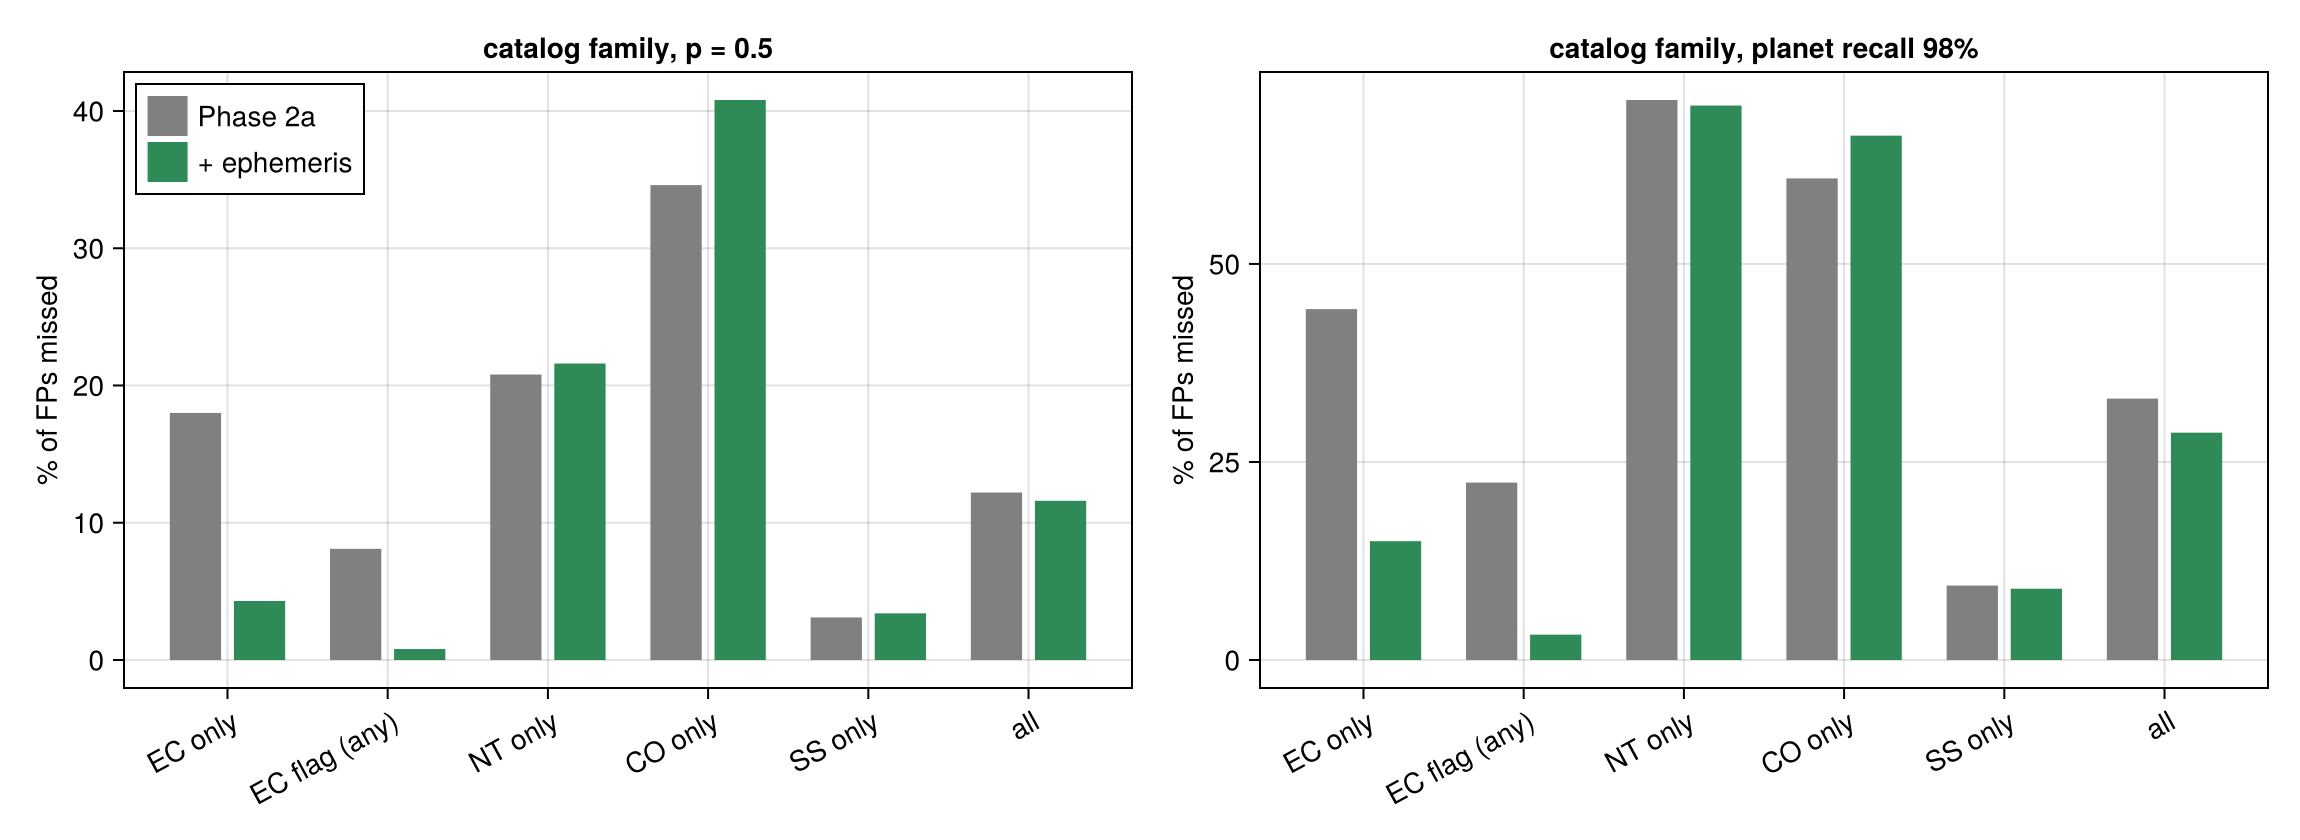

In [5]:
crit = readres("p3_m2_criteria.csv")
show(stdout, MIME"text/plain"(), crit; allrows = true, allcols = true)
fig = Figure(size = (1150, 420))
for (j, rule) in enumerate(("p = 0.5", "planet recall 98%"))
    t = crit[(crit.rule .== rule) .& (crit.family .== "catalog") .& startswith.(crit.group, "FP missed"), :]
    ax = Axis(fig[1, j]; xticks = (1:nrow(t), replace.(t.group, "FP missed: " => "")), xticklabelrotation = 0.5,
              ylabel = "% of FPs missed", title = "catalog family, $rule")
    barplot!(ax, (1:nrow(t)) .- 0.2, t.old_pct; width = 0.4, color = :gray, label = "Phase 2a")
    barplot!(ax, (1:nrow(t)) .+ 0.2, t.new_pct; width = 0.4, color = :seagreen, label = "+ ephemeris")
    j == 1 && axislegend(ax; position = :lt)
end
fig

**Main criterion met in both families.** EC-only FPs missed at p = 0.5 fall **18.0 → 4.3%** (catalog) and
**23.2 → 6.7%** (+ centroid), both below the 15% target with CIs far from 0. At the 98% recall headline they fall
44.3 → 15.0% and 33.7 → 13.3%. Over all 1,022 EC-flagged FPs, misses at 98% recall drop from 22.4% to 3.2% (catalog).

**No regressions in the plan's terms:** DR25 AUC rises, and CONFIRMED planets lost at 98% recall stay at
0.4% / 0.3–0.4% (Δ 0.0, CI ±0.1–0.2).

**One side effect: centroid-offset (CO-only) FPs.** In the catalog family, misses rise 34.6 → 40.8% at p = 0.5 and
60.8 → 66.2% at 98% recall (CIs above 0). These are signals from a faint star next to the target, which usually is
not a Kepler target, so it has no TCE to match. The model learns that "no match" lowers the odds of an FP, and
these KOIs have no match. In the + centroid family, where the centroid features catch them, the effect is small
(5.3 → 6.7%). The FPs missed overall still fall in both families.

## 5. Operating points, and the robovetter at low FP rates

In [6]:
menu = readres("p3_m2_operating_points.csv")
menu[in.(menu.rule, Ref(("planet recall 98%", "planet recall 95%", "p = 0.5"))),
     [:family, :model, :rule, :t_median, :dr25_recall, :dr25_precision, :dr25_fp_kept, :fps_kept_per1000, :confirmed_lost]]

Row,family,model,rule,t_median,dr25_recall,dr25_precision,dr25_fp_kept,fps_kept_per1000,confirmed_lost
,DataStri…,DataStri…,DataStri…,Float64,Float64,Float64,Float64,Int64,Float64
1,catalog,Phase 2a,planet recall 95%,0.358,0.949,0.865,0.156,76,0.011
2,catalog,Phase 2a,planet recall 98%,0.178,0.98,0.805,0.251,122,0.004
3,catalog,Phase 2a,p = 0.5,0.5,0.919,0.905,0.101,49,0.02
4,catalog,+ ephemeris,planet recall 95%,0.4,0.95,0.891,0.123,60,0.01
5,catalog,+ ephemeris,planet recall 98%,0.199,0.98,0.835,0.204,99,0.004
6,catalog,+ ephemeris,p = 0.5,0.5,0.93,0.914,0.093,45,0.016
7,+ centroid,Phase 2a,planet recall 95%,0.492,0.949,0.935,0.069,34,0.007
8,+ centroid,Phase 2a,planet recall 98%,0.25,0.979,0.882,0.138,67,0.003
9,+ centroid,Phase 2a,p = 0.5,0.5,0.948,0.938,0.066,32,0.007


10×6 DataFrame
 Row │ fp_rate  family      model        n      recall   spread
     │ Float64  DataStri…   DataStri…    Int64  Float64  Float64
─────┼───────────────────────────────────────────────────────────
   1 │    0.05  catalog     Phase 2a      7199    0.849    0.004
   2 │    0.05  catalog     + ephemeris   7199    0.88     0.002
   3 │    0.05  + centroid  Phase 2a      7199    0.935    0.001
   4 │    0.05  + centroid  + ephemeris   7199    0.946    0.001
   5 │    0.05  reference   koi_score     7199    0.953    0.0
   6 │    0.1   catalog     Phase 2a      7199    0.918    0.002
   7 │    0.1   catalog     + ephemeris   7199    0.936    0.002
   8 │    0.1   + centroid  Phase 2a      7199    0.966    0.002
   9 │    0.1   + centroid  + ephemeris   7199    0.973    0.001
  10 │    0.1   reference   koi_score     7199    0.968    0.0


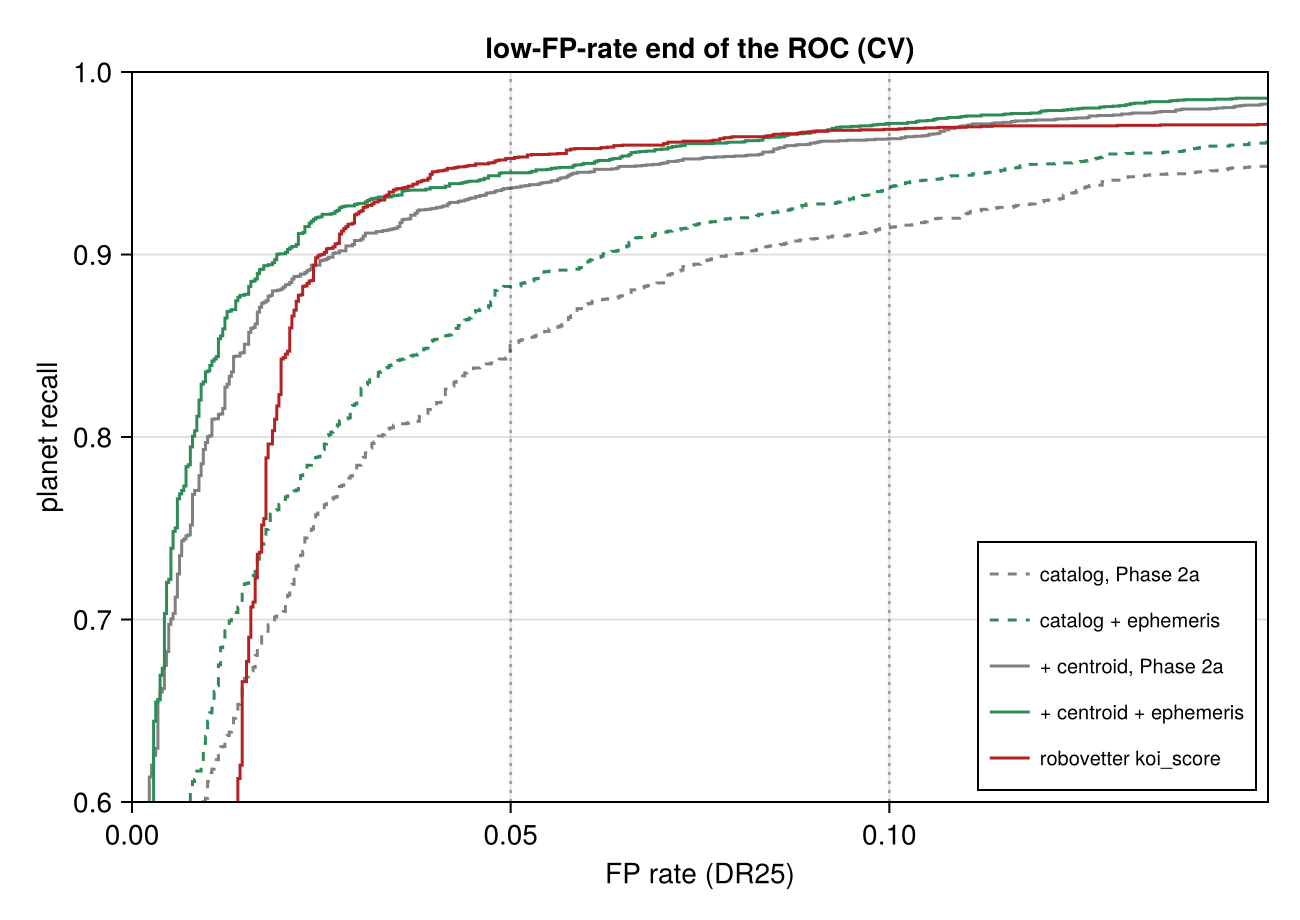

In [7]:
low = readres("p3_m2_lowfp.csv")
show(stdout, MIME"text/plain"(), low; allrows = true); println()
# DR25 ROC at low FP rate, from the saved CV (first fold shuffle) and koi_score
ks = Float64.(coalesce.(leftjoin(pool[:, [:kepoi_name]], df_raw[:, [:kepoi_name, :koi_score]];
                                 on = :kepoi_name, order = :left).koi_score, NaN))
avgS(a, b) = (repeat_scores(load_cv(a)) .+ repeat_scores(load_cv(b))) ./ 2
curves = [("catalog, Phase 2a", avgS("cv_mlpq_lc_r5s10.jld2", "cv_evotree_lc_r5s10.jld2"), :gray, :dash),
          ("catalog + ephemeris", avgS("cv_mlpq_eph_r5s10.jld2", "cv_evotree_eph_r5s10.jld2"), :seagreen, :dash),
          ("+ centroid, Phase 2a", avgS("cv_mlpq_lccent_r5s10.jld2", "cv_evotree_lccent_r5s10.jld2"), :gray, :solid),
          ("+ centroid + ephemeris", avgS("cv_mlpq_centeph_r5s10.jld2", "cv_evotree_centeph_r5s10.jld2"), :seagreen, :solid)]
m = dr .& isfinite.(ks)
function roc_pts(yy, s)
    o = sortperm(s; rev = true)
    return cumsum(yy[o] .== 0) ./ sum(yy .== 0), cumsum(yy[o] .== 1) ./ sum(yy .== 1)
end
fig = Figure(size = (650, 460))
ax = Axis(fig[1, 1]; xlabel = "FP rate (DR25)", ylabel = "planet recall", title = "low-FP-rate end of the ROC (CV)")
for (lab, Sm, c, ls) in curves
    fpr, tpr = roc_pts(y[m], Sm[m, 1]); lines!(ax, fpr, tpr; color = c, linestyle = ls, label = lab)
end
fpr, tpr = roc_pts(y[m], ks[m]); lines!(ax, fpr, tpr; color = :firebrick, label = "robovetter koi_score")
vlines!(ax, [0.05, 0.10]; color = (:black, 0.3), linestyle = :dot)
limits!(ax, 0, 0.15, 0.6, 1.0); axislegend(ax; position = :rb, labelsize = 10)
fig

- **At 98% planet recall**, the FPs kept fall 25 → 20% (catalog) and 14 → 12% (+ centroid) on DR25 KOIs.
  Precision rises 0.805 → 0.835 and 0.882 → 0.896.
- **Against the robovetter** (`koi_score`, which comes from the same vetting that set the labels, so it is a
  reference, not a benchmark): the + centroid + ephemeris model now **beats it at a 10% FP rate (0.973 vs 0.968)**
  and nearly matches it at 5% (0.946 vs 0.953). In the catalog family the gap at 5% narrows from 0.849 to 0.880,
  against 0.953.
- The curves (one fold shuffle) show where the robovetter still leads: only between FP rates of roughly 3% and 9%.
  Below ~3% both + centroid models already beat it, and the ephemeris features widen that lead.

## 6. v2: adding the Kepler eclipsing-binary catalog

The EB catalog (Kirk et al. 2016, 2,876 EBs; VizieR `J/AJ/151/68`) was unreachable at M0. It came back on the
CfA mirror on 11/08, so it was added as a pre-planned v2 (`p3_match.jl --eb`, `p3_cv.jl --eb`). It has periods,
epochs and the star's magnitude, but no depths, so an EB match takes its leak fraction from the best match with a
known depth.

In [8]:
readres("p3_m2eb_summary.csv")

Row,family,subset,n,old,auc_old,new,auc_new,delta,ci_lo,ci_hi
,DataStri…,DataStri…,Int64,DataStri…,Float64,DataStri…,Float64,Float64,Float64,Float64
1,catalog,DR25 KOIs,7199,+ ephemeris,0.9764,+ eph + EB,0.9764,-0.0001,-0.0001,0.0
2,catalog,supplemental KOIs,1089,+ ephemeris,0.6979,+ eph + EB,0.699,0.0011,-0.0003,0.0025
3,catalog,all pool,8288,+ ephemeris,0.9605,+ eph + EB,0.9605,-0.0,-0.0001,0.0001
4,+ centroid,DR25 KOIs,7199,+ ephemeris,0.9889,+ eph + EB,0.989,0.0,-0.0,0.0001
5,+ centroid,supplemental KOIs,1089,+ ephemeris,0.769,+ eph + EB,0.769,-0.0,-0.0012,0.001
6,+ centroid,all pool,8288,+ ephemeris,0.9778,+ eph + EB,0.9778,0.0,-0.0,0.0001


In [9]:
crit2 = readres("p3_m2eb_criteria.csv")
crit2[startswith.(crit2.group, "FP missed: EC") .| startswith.(crit2.group, "CONFIRMED called FP ("), :]

Row,group,n,family,rule,old_pct,new_pct,delta_pct,ci_lo,ci_hi
,DataStri…,Int64,DataStri…,DataStri…,Float64,Float64,Float64,Float64,Float64
1,FP missed: EC only,111,catalog,p = 0.5,4.3,4.3,0.0,0.0,0.0
2,FP missed: EC only,111,catalog,planet recall 98%,15.0,15.1,0.2,-0.4,0.7
3,FP missed: EC only,111,+ centroid,p = 0.5,6.7,6.8,0.2,0.0,0.5
4,FP missed: EC only,111,+ centroid,planet recall 98%,13.3,13.2,-0.2,-0.5,0.0
5,FP missed: EC flag (any),1022,catalog,p = 0.5,0.8,0.8,-0.0,-0.1,0.0
6,FP missed: EC flag (any),1022,catalog,planet recall 98%,3.2,3.2,0.0,-0.3,0.3
7,FP missed: EC flag (any),1022,+ centroid,p = 0.5,0.8,0.8,0.0,0.0,0.1
8,FP missed: EC flag (any),1022,+ centroid,planet recall 98%,2.3,2.3,0.1,-0.0,0.3
9,CONFIRMED called FP (DR25),2459,catalog,p = 0.5,1.6,1.6,0.0,-0.0,0.1


**The EB catalog adds nothing measurable.** It brings ~15 more real near matches, and the EC-flagged FPs with a
near match go from 86.0 to 89.2% in the pool check, but every AUC and blind-spot change vs v1 is ≈ 0 (|Δ| ≤ 0.5
points). Most catalogued EBs are already DR25 TCEs, so v1 had them. **v1 (KOIs + TCEs) stays the Phase 3 model**:
fewer inputs, the same result.

## 7. Conclusions

1. **Ephemeris matching closes the contamination blind spot.** EC-only FPs missed at p = 0.5 fall 18.0 → 4.3%
   (catalog) and 23.2 → 6.7% (+ centroid), well below the 15% target, with paired CIs far from 0. At 98% recall they
   fall 44 → 15% and 34 → 13%.
2. **The whole model improves, not only that group.** DR25 AUC 0.971 → 0.976 and 0.987 → 0.989 (CIs > 0). At 98%
   planet recall the FPs kept fall 25 → 20% and 14 → 12%, with no change in CONFIRMED planets lost.
3. **Against the robovetter at low FP rates,** the + centroid + ephemeris model now edges past `koi_score` at a 10%
   FP rate (0.973 vs 0.968) and nearly matches it at 5% (0.946 vs 0.953).
4. **Caveats.**
   - The features re-implement Kepler's own EC test, so this family is partly circular with the labels, like
     "+ centroid". That is why it is a separate family.
   - In the catalog family, centroid-offset FPs (sources that are not Kepler targets) get slightly harder to catch.
   - CV only: the test set is spent, so these numbers have no independent test confirmation.
5. **Open, for the user:** adopt the "+ ephemeris" models (freezing them would be labelled "post-test,
   CV-validated"), and whether the NT blind spot (still ~21–24% missed at p = 0.5) comes next.